In [15]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

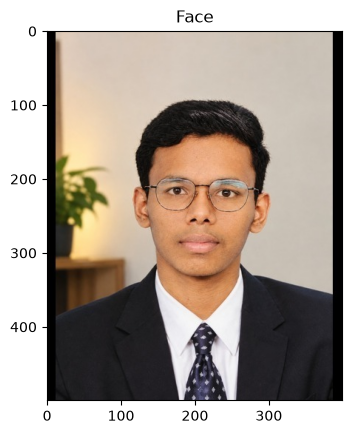

In [16]:
# Load the Face Image
faceImage = cv2.imread("passport (1).jpg")
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [17]:
faceImage.shape

(500, 400, 3)

In [18]:
#resized_faceImage.shape
faceImage.shape

(500, 400, 3)

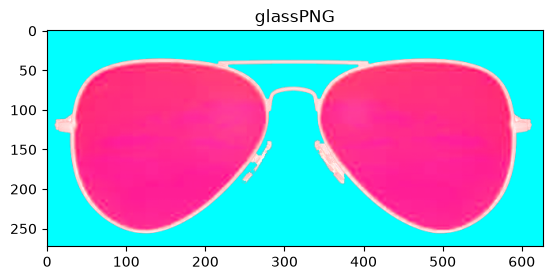

In [19]:
glassPNG = cv2.imread('sunglass-png-aviator-sunglass-png-pic-627.png', -1)
plt.imshow(glassPNG[:, :, ::-1])
plt.title("glassPNG")
plt.show()

In [20]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(50, 190, 4)


In [21]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

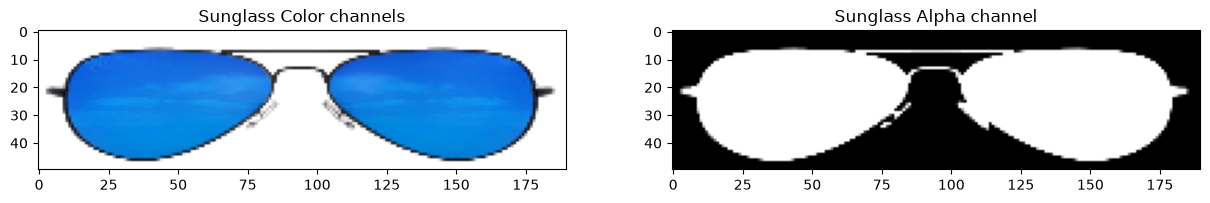

In [22]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

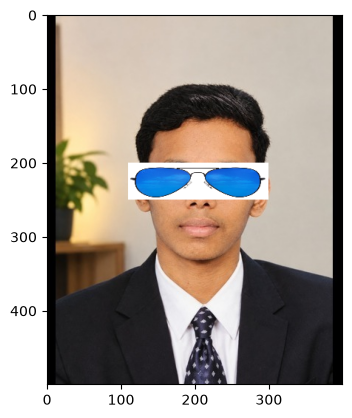

In [23]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()

# Resize sunglasses to match the eye region
glassBGR = cv2.resize(glassBGR, (190, 50))

# Replace the eye region with the sunglass image
faceWithGlassesNaive[200:250, 110:300] = glassBGR

# Display the result
plt.imshow(faceWithGlassesNaive[..., ::-1])
plt.show()

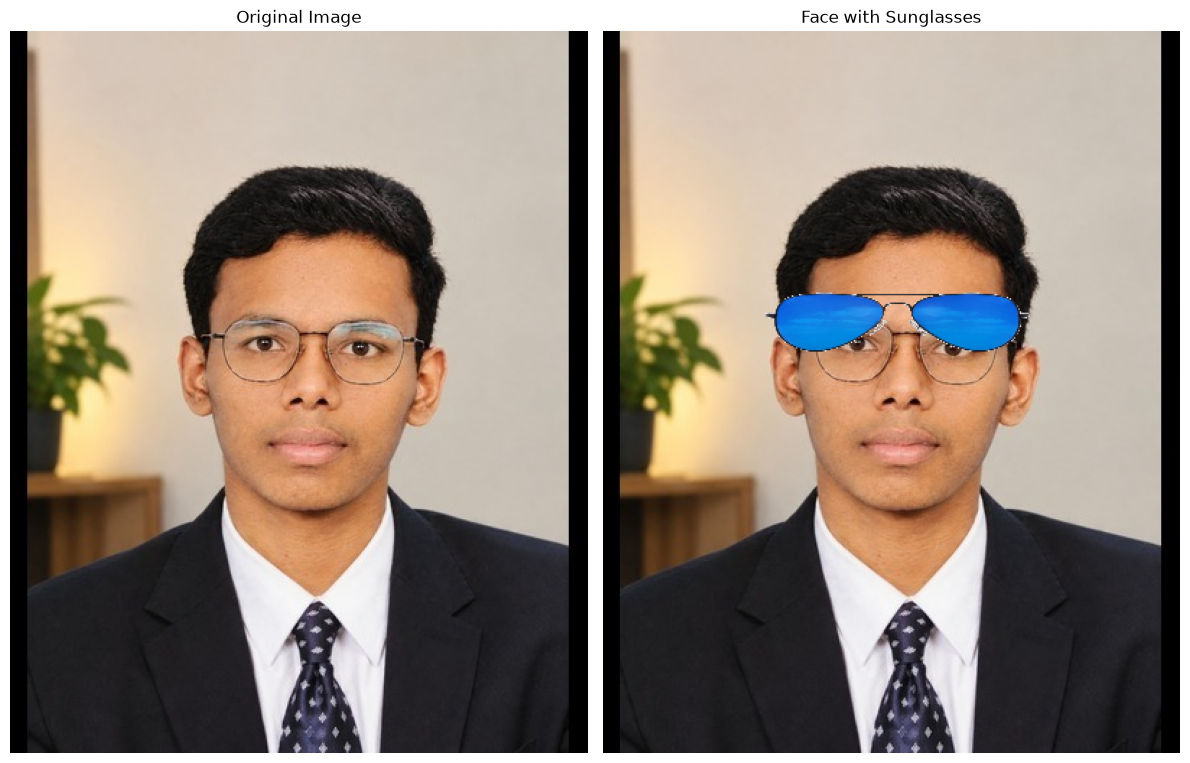

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Copy the original face image
faceWithGlasses = faceImage.copy()

# Step 2: Define the eye region coordinates
x, y, w, h = 110, 175, 190, 50

# Step 3: Resize sunglasses to fit the eye region
glassBGR = cv2.resize(glassBGR, (w, h))

# Step 4: Extract the eye region
eyeROI = faceWithGlasses[y:y+h, x:x+w]

# Step 5: Create a grayscale mask
glassGray = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)

_, glassMask = cv2.threshold(
    glassGray, 240, 255, cv2.THRESH_BINARY_INV
)

# Step 6: Normalize the mask
glassMask = glassMask.astype(np.float32) / 255.0

# Convert the mask into 3 channels
glassMask = cv2.merge([glassMask, glassMask, glassMask])

# Step 7: Convert images to float
eyeROI = eyeROI.astype(np.float32)
glassBGR = glassBGR.astype(np.float32)

# Step 8: Blend the sunglasses with the eye region
maskedEye = eyeROI * (1 - glassMask)
maskedGlass = glassBGR * glassMask

eyeRoiFinal = maskedEye + maskedGlass

# Step 9: Convert back to uint8
eyeRoiFinal = np.clip(eyeRoiFinal, 0, 255).astype(np.uint8)

# Step 10: Place sunglasses on the face
faceWithGlasses[y:y+h, x:x+w] = eyeRoiFinal

# Step 11: Display original and final images
plt.figure(figsize=(12, 8))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(faceWithGlasses, cv2.COLOR_BGR2RGB))
plt.title("Face with Sunglasses")
plt.axis("off")

plt.tight_layout()
plt.show()